# **Exploratory Data Analysis**

EDA helps us understand a dataset before modeling. We will inspect its size, types, missing values, distributions, and relationships using the Titanic data, then finish with automated profiling and the feature-engineering workflow.


## **Understanding the data**

Start with a few basic questions: How big is the data? What do the rows look like? Which columns are missing values or duplicated? What do the numeric summaries and relationships show?


In [1]:
from pathlib import Path
import pandas as pd

DATA_PATH = "/kaggle/input/competitions/titanic/train.csv"
if DATA_PATH is None:
    raise FileNotFoundError("Add Titanic train.csv and update DATA_PATH to its location.")

df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.lower()
print("Shape:", df.shape)
df.head()


Shape: (891, 12)


,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


This file has 891 rows and 12 columns. `head()` gives a quick look at the values; use `sample()` when you want to inspect a few rows from different parts of the table.


In [2]:
df.sample(5, random_state=42)


,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
709,710,1,3,"Moubarek, Master. Halim Gonios (""William George"")",male,NaN,1,1,2661,15.2458,NaN,C
439,440,0,2,"Kvillner, Mr. Johan Henrik Johannesson",male,31.0,0,0,C.A. 18723,10.5000,NaN,S
840,841,0,3,"Alhomaki, Mr. Ilmari Rudolf",male,20.0,0,0,SOTON/O2 3101287,7.9250,NaN,S
720,721,1,2,"Harper, Miss. Annie Jessie ""Nina""",female,6.0,0,1,248727,33.0000,NaN,S
39,40,1,3,"Nicola-Yarred, Miss. Jamila",female,14.0,1,0,2651,11.2417,NaN,C


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   passengerid  891 non-null    int64  
 1   survived     891 non-null    int64  
 2   pclass       891 non-null    int64  
 3   name         891 non-null    object 
 4   sex          891 non-null    object 
 5   age          714 non-null    float64
 6   sibsp        891 non-null    int64  
 7   parch        891 non-null    int64  
 8   ticket       891 non-null    object 
 9   fare         891 non-null    float64
 10  cabin        204 non-null    object 
 11  embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


`info()` shows each column's data type and non-null count. Here, `Age`, `Cabin`, and `Embarked` have missing values, so we should check their counts before deciding what to do.


In [4]:
missing = df.isna().sum().sort_values(ascending=False)
missing_percent = (df.isna().mean() * 100).sort_values(ascending=False)
pd.DataFrame({"missing values": missing, "missing %": missing_percent.round(1)})


,missing values,missing %
cabin,687,77.1
age,177,19.9
embarked,2,0.2
passengerid,0,0.0
name,0,0.0
pclass,0,0.0
survived,0,0.0
sex,0,0.0
parch,0,0.0
sibsp,0,0.0


`Cabin` is missing for about 77% of passengers, while `Age` is missing for about 20%. The 60–70% cutoff in the notes is a rough decision aid, not a rule: consider what a column means and whether its missingness itself carries information.


In [5]:
print("Duplicate rows:", df.duplicated().sum())
df.describe().T


Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
passengerid,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
sibsp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


The file has no duplicate rows. `describe()` summarizes numeric columns; the median can be more representative than the mean when values are skewed.


In [6]:
df["age"].agg(["min", "median", "max"])


min        0.42
median    28.00
max       80.00
Name: age, dtype: float64

A correlation table summarizes linear association between numeric columns. The `survived` column is 0/1, so its correlation gives a compact association check with the other numeric columns.


In [7]:
correlation = df.select_dtypes(include="number").corr()
correlation.round(2)


,passengerid,survived,pclass,age,sibsp,parch,fare
passengerid,1.00,-0.01,-0.04,0.04,-0.06,-0.00,0.01
survived,-0.01,1.00,-0.34,-0.08,-0.04,0.08,0.26
pclass,-0.04,-0.34,1.00,-0.37,0.08,0.02,-0.55
age,0.04,-0.08,-0.37,1.00,-0.31,-0.19,0.10
sibsp,-0.06,-0.04,0.08,-0.31,1.00,0.41,0.16
parch,-0.00,0.08,0.02,-0.19,0.41,1.00,0.22
fare,0.01,0.26,-0.55,0.10,0.16,0.22,1.00


In [8]:
survival_correlation = correlation["survived"].drop("survived").sort_values(ascending=False)
survival_correlation


fare           0.257307
parch          0.081629
passengerid   -0.005007
sibsp         -0.035322
age           -0.077221
pclass        -0.338481
Name: survived, dtype: float64

In this sample, `pclass` has a negative association with survival and `fare` a positive one. Correlation is not causation, and a small correlation alone is not a sound reason to remove a feature.


In [9]:
memory_before = df.memory_usage(deep=True).sum()
compact = df.copy()

for column in compact.select_dtypes(include="integer"):
    compact[column] = pd.to_numeric(compact[column], downcast="integer")
for column in compact.select_dtypes(include="floating"):
    compact[column] = pd.to_numeric(compact[column], downcast="float")

memory_after = compact.memory_usage(deep=True).sum()
print(f"Before: {memory_before:,} bytes")
print(f"After:  {memory_after:,} bytes")
print(compact[["pclass", "age", "fare"]].dtypes)


Before: 292,464 bytes
After:  255,042 bytes
pclass       int8
age       float32
fare      float32
dtype: object


Downcasting uses a smaller numeric type when it can represent the values. Integer columns can often use smaller integers; continuous measurements should not be converted to integers because that would discard fractional information.


## **Univariate analysis**

Univariate analysis looks at one variable at a time. First identify whether a column is categorical or numerical, then choose a summary or plot that suits it.


In [10]:
df["survived"].value_counts().sort_index()


survived
0    549
1    342
Name: count, dtype: int64

For a categorical column, a count plot or bar chart shows how many rows belong to each category. This count plot shows how many passengers survived and how many did not.


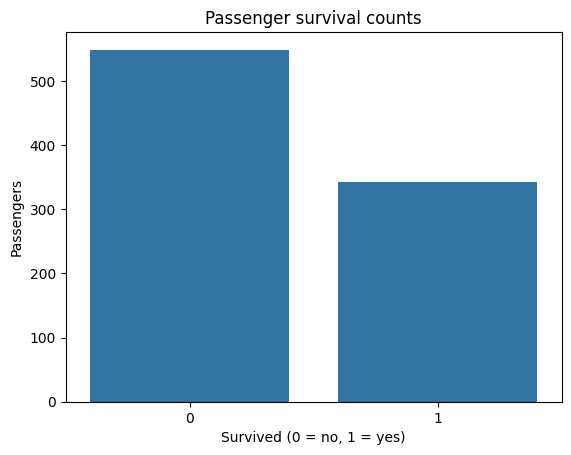

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="survived")
plt.title("Passenger survival counts")
plt.xlabel("Survived (0 = no, 1 = yes)")
plt.ylabel("Passengers")
plt.show()


A pie chart shows the same categories as proportions. It is useful for a small number of categories, though a bar chart is usually easier to compare accurately.


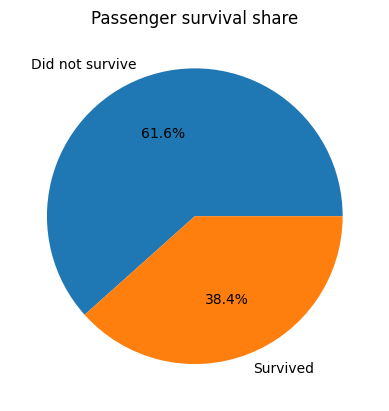

In [12]:
df["survived"].value_counts().sort_index().plot(
    kind="pie", labels=["Did not survive", "Survived"],
    autopct="%.1f%%", ylabel="", title="Passenger survival share"
)
plt.show()


A histogram groups numerical values into bins (ranges). Changing the number of bins changes how much detail is visible, so check that the chosen view does not hide the shape of the data.


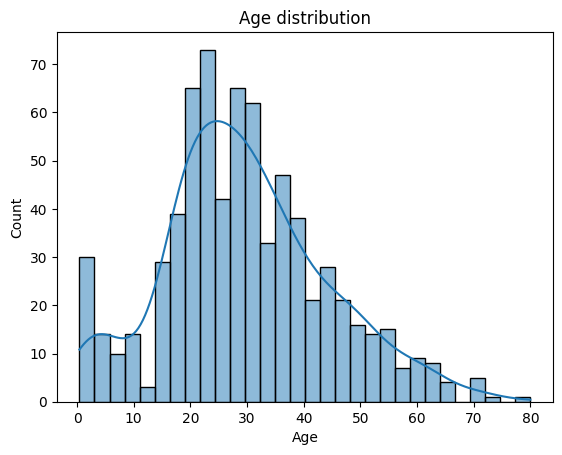

In [13]:
sns.histplot(data=df, x="age", bins=30, kde=True)
plt.title("Age distribution")
plt.xlabel("Age")
plt.show()


The smooth curve is a kernel density estimate (KDE), an estimate of the distribution's shape. It is not the probability of one exact age; use the histogram and KDE together to notice concentration and skew.


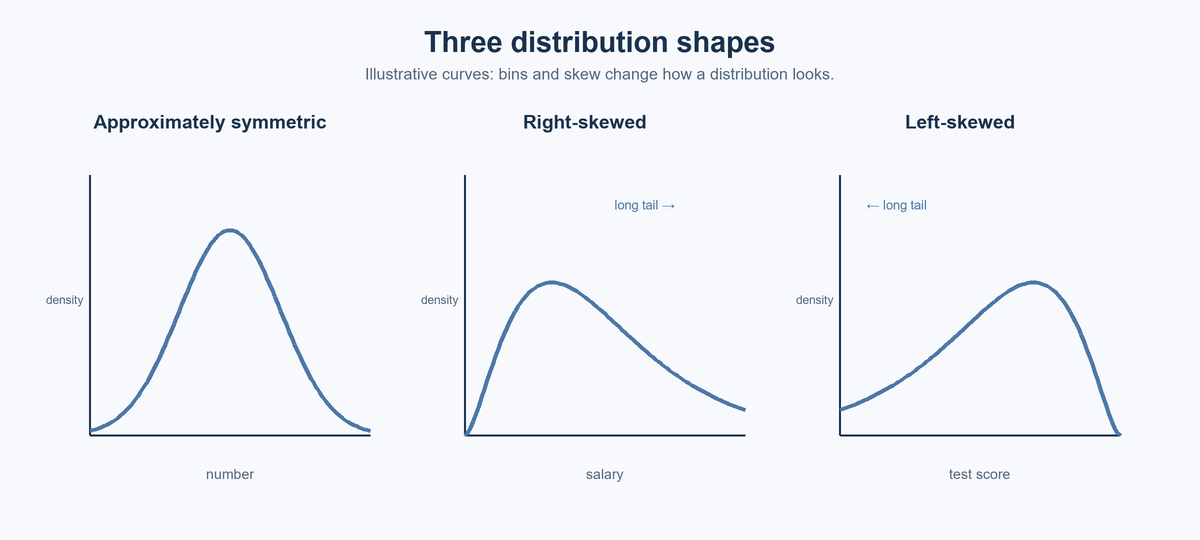

In [14]:
age_skew = df["age"].skew()
print(f"Age skewness: {age_skew:.3f}")


Age skewness: 0.389


A positive value means the distribution has a longer right tail; a negative value means a longer left tail. Age has a small positive skew in this dataset, so it is only mildly right-skewed. A value near zero suggests approximate symmetry, not perfect symmetry.


A box plot summarizes the middle half of the data with the interquartile range, $IQR = Q_3 - Q_1$. Values beyond the usual $1.5 \times IQR$ fences are flagged for inspection; they should not be removed automatically.


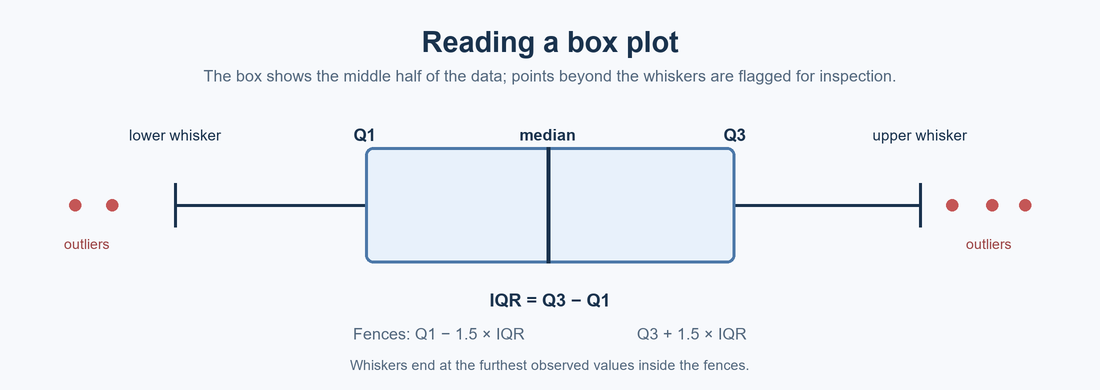


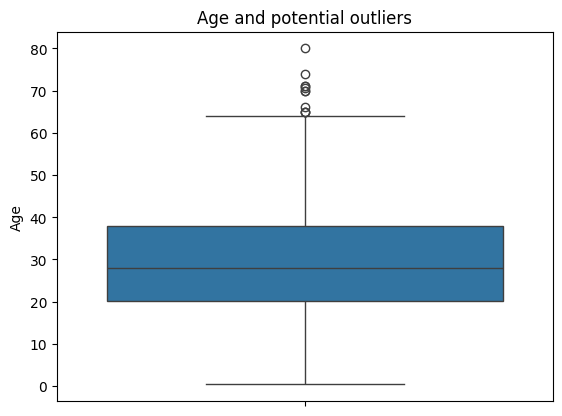

In [15]:
sns.boxplot(data=df, y="age")
plt.title("Age and potential outliers")
plt.ylabel("Age")
plt.show()


The whiskers end at the furthest observed values inside the fences, not necessarily at the minimum and maximum. The marked points are candidates to investigate, not proof of incorrect data.


<!-- Source transcription: transcription/9.2.md -->
## Bivariate and multivariate analysis

Bivariate analysis compares two variables; multivariate analysis considers several together. A scatter plot is useful for two numerical variables, and color, marker style, or size can add another variable.


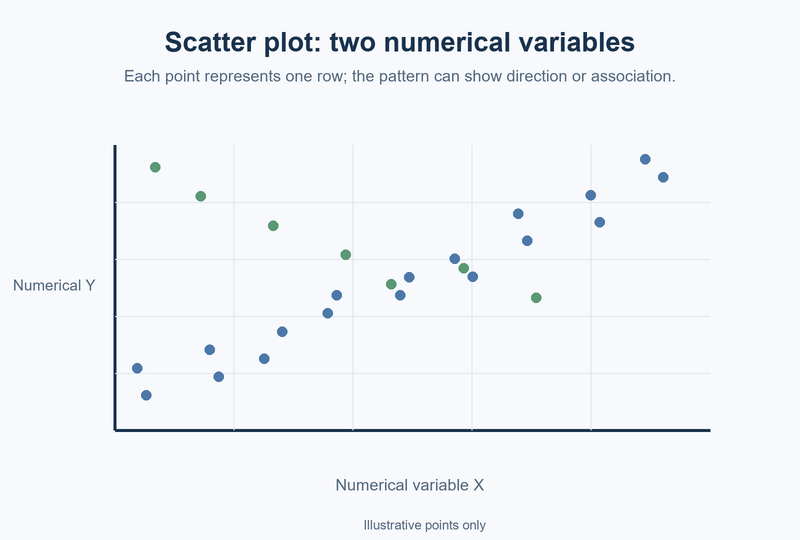

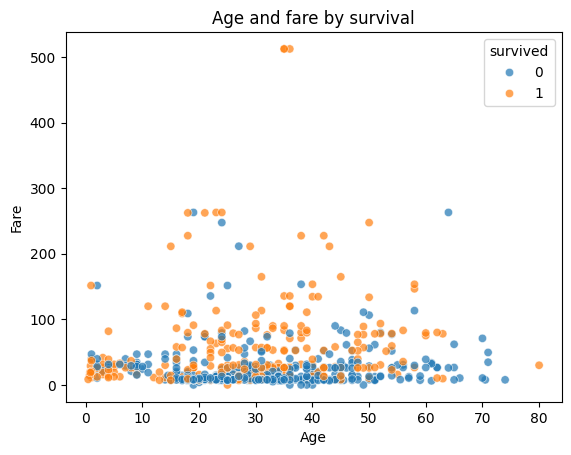

In [16]:
sns.scatterplot(data=df, x="age", y="fare", hue="survived", alpha=0.7)
plt.title("Age and fare by survival")
plt.xlabel("Age")
plt.ylabel("Fare")
plt.show()


Each point is a passenger. The colors let us compare survival groups, but overlapping points and missing ages limit what this plot can show; it does not establish why survival differed.


Color, marker style, and point size can show additional columns in one scatter plot. This view uses sex, survival, and family size alongside age and fare; too many encodings can make a plot harder to read, so add them only when they help.


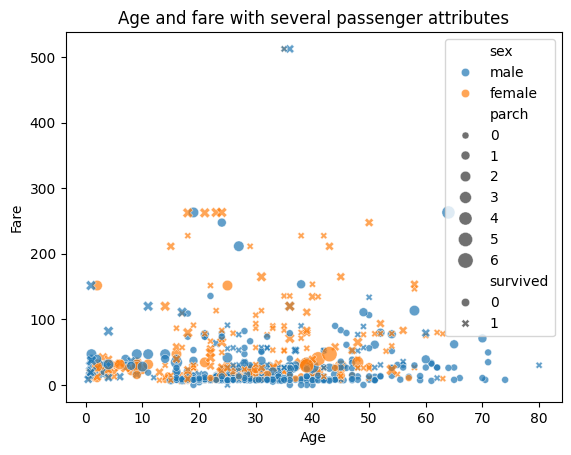

In [17]:
sns.scatterplot(
    data=df, x="age", y="fare", hue="sex",
    style="survived", size="parch", sizes=(25, 120), alpha=0.7
)
plt.title("Age and fare with several passenger attributes")
plt.xlabel("Age")
plt.ylabel("Fare")
plt.show()


A bar plot can compare a numerical outcome across categories. Here the mean of the 0/1 `survived` column is the survival rate for each passenger class.


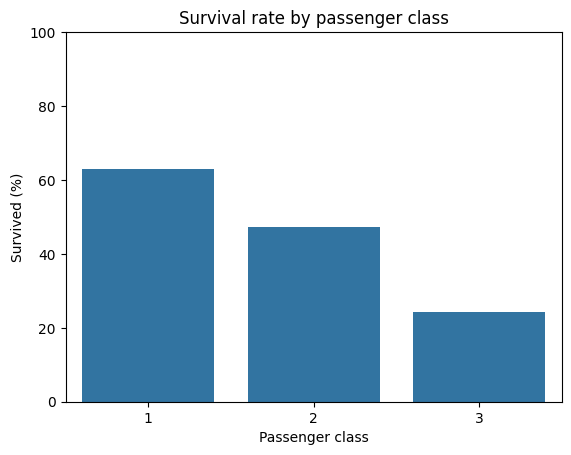

pclass
1    63.0
2    47.3
3    24.2
Name: survived, dtype: float64

In [18]:
survival_by_class = df.groupby("pclass")["survived"].mean().mul(100)
sns.barplot(x=survival_by_class.index, y=survival_by_class.values, errorbar=None)
plt.title("Survival rate by passenger class")
plt.xlabel("Passenger class")
plt.ylabel("Survived (%)")
plt.ylim(0, 100)
plt.show()
survival_by_class.round(1)


In this sample, survival rates were about 63% in first class, 47% in second, and 24% in third. These are descriptive comparisons for this dataset, not a causal conclusion.


A box plot can compare a numerical distribution across categories. The hue adds survival status so we can compare passenger ages across both sex and outcome.


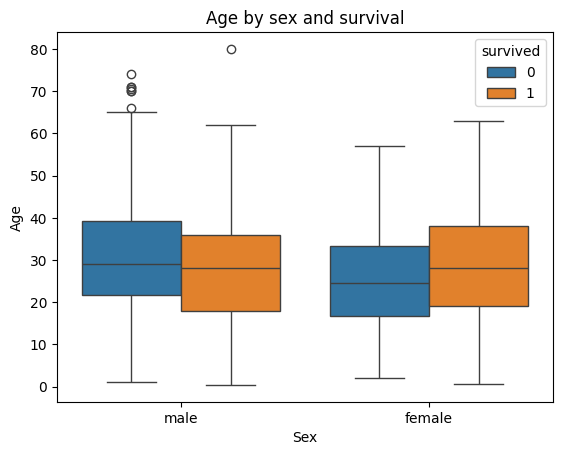

In [19]:
sns.boxplot(data=df, x="sex", y="age", hue="survived")
plt.title("Age by sex and survival")
plt.xlabel("Sex")
plt.ylabel("Age")
plt.show()


A KDE plot compares estimated age distributions for passengers who survived and those who did not. In this dataset, the survivor curve is more concentrated among younger ages, but the curves overlap; this is a pattern, not a guarantee about an individual passenger.


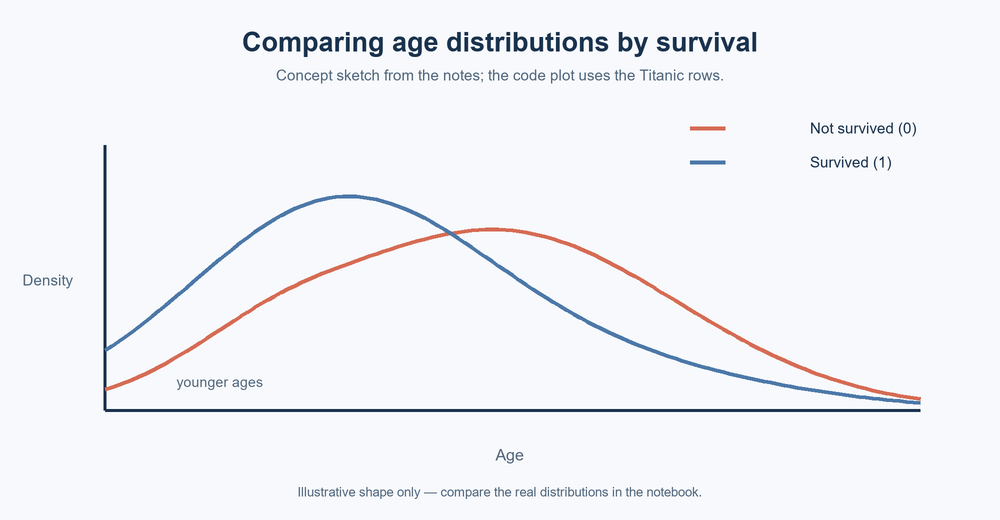


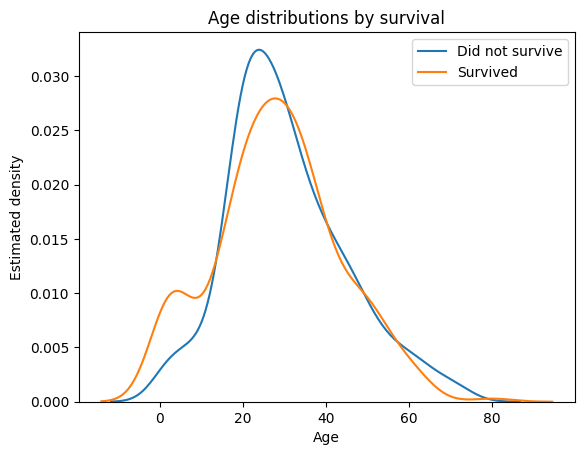

In [20]:
for survived, label in [(0, "Did not survive"), (1, "Survived")]:
    ages = df.loc[df["survived"] == survived, "age"].dropna()
    sns.kdeplot(x=ages, label=label, fill=False)
plt.title("Age distributions by survival")
plt.xlabel("Age")
plt.ylabel("Estimated density")
plt.legend()
plt.show()


### **Categorical relationships**

A crosstab counts combinations of categories. A heatmap colors those counts, while a row-normalized table or grouped mean is better for comparing rates across groups of different sizes.


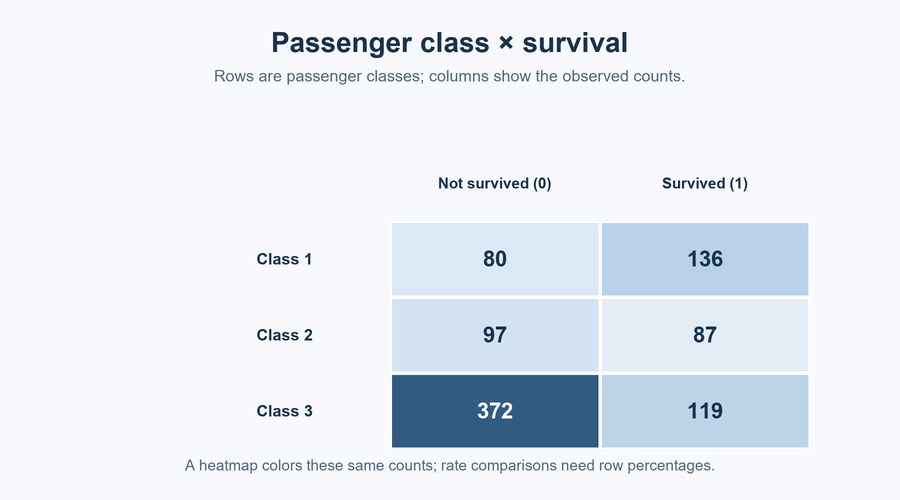


In [21]:
class_survival = pd.crosstab(df["pclass"], df["survived"])
class_survival


survived,0,1
pclass,,
1,80,136
2,97,87
3,372,119


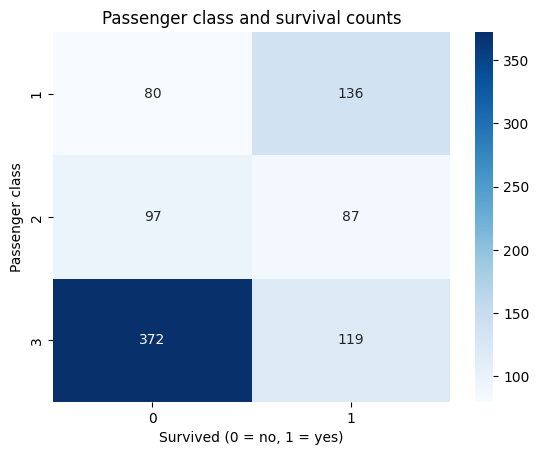

In [22]:
sns.heatmap(class_survival, annot=True, fmt="d", cmap="Blues")
plt.title("Passenger class and survival counts")
plt.xlabel("Survived (0 = no, 1 = yes)")
plt.ylabel("Passenger class")
plt.show()


The heatmap shows counts, so the larger third-class group naturally has larger cells. To compare each class fairly, look at row percentages or the survival rate.


In [23]:
class_percent = pd.crosstab(
    df["pclass"], df["survived"], normalize="index"
).mul(100)
class_percent.round(1)


survived,0,1
pclass,,
1,37.0,63.0
2,52.7,47.3
3,75.8,24.2


A clustermap adds hierarchical clustering to the rows and columns, arranging categories with similar count patterns near one another. The dendrogram summarizes those similarities; it does not prove the groups are meaningfully related.


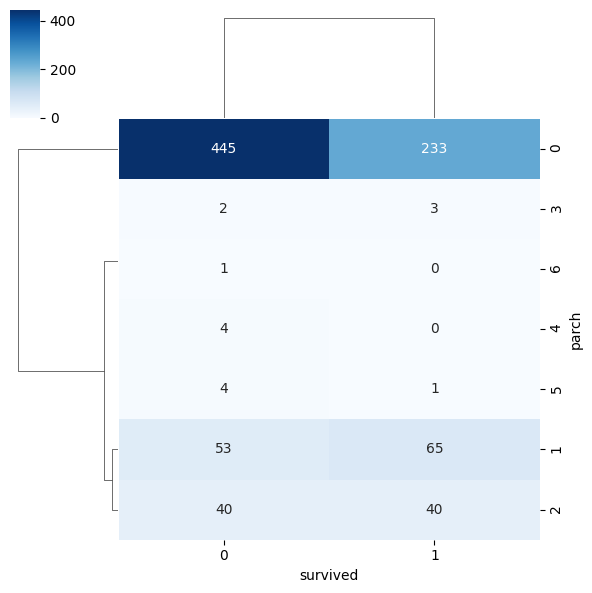

In [24]:
parch_survival = pd.crosstab(df["parch"], df["survived"])
sns.clustermap(parch_survival, annot=True, fmt="d", cmap="Blues", figsize=(6, 6))
plt.show()


A pair plot gives a grid of plots for several numerical columns. The Iris example below follows the original code; `hue` colors observations by species. Seaborn may download this small example dataset the first time it is requested.


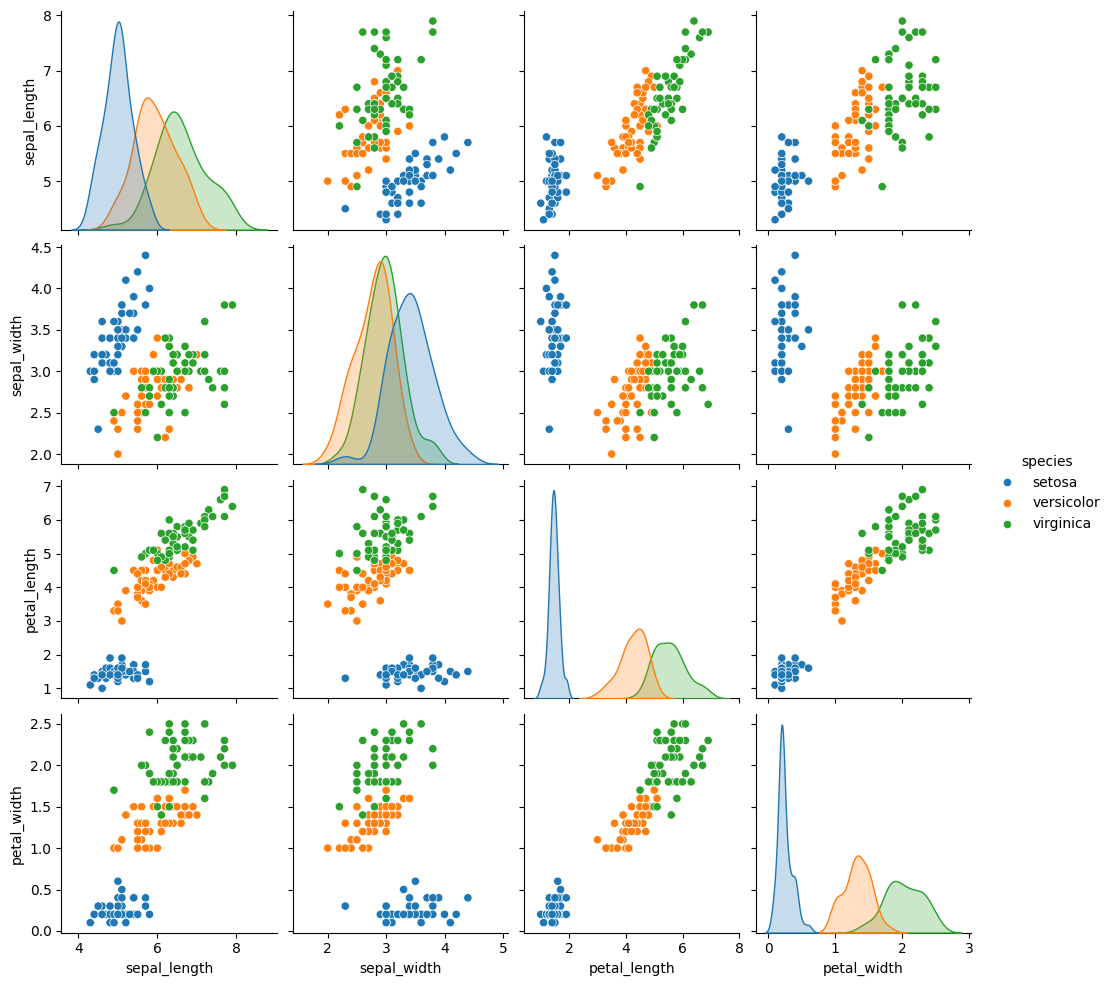

In [25]:
iris = sns.load_dataset("iris")
sns.pairplot(iris, hue="species")
plt.show()


For data recorded over time, a line plot makes the time variable the x-axis. The flights example groups passenger counts by year before plotting. Seaborn may need an internet connection to fetch the sample dataset.


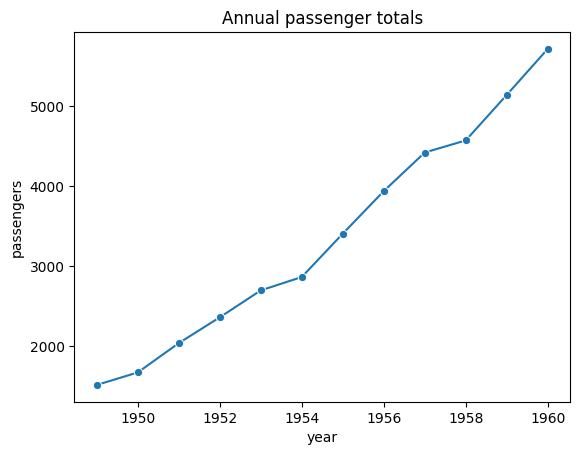

In [26]:
flights = sns.load_dataset("flights")
passengers_by_year = flights.groupby("year", as_index=False)["passengers"].sum()
sns.lineplot(data=passengers_by_year, x="year", y="passengers", marker="o")
plt.title("Annual passenger totals")
plt.show()


A pivot table rearranges the flight data so months are rows and years are columns. The heatmap makes seasonal and year-to-year patterns easier to scan.


/tmp/ipykernel_16/1875856324.py:1: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  monthly_flights = flights.pivot_table(


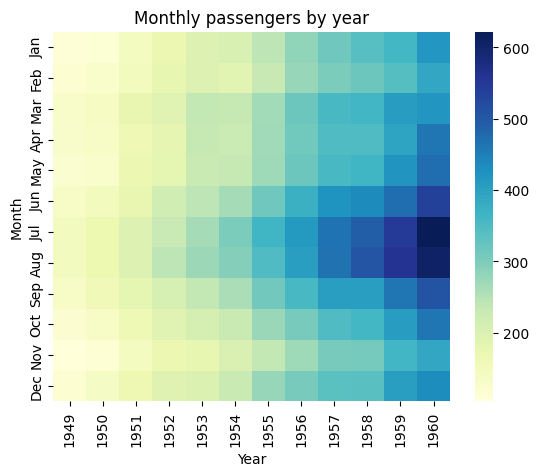

In [27]:
monthly_flights = flights.pivot_table(
    values="passengers", index="month", columns="year"
)
sns.heatmap(monthly_flights, cmap="YlGnBu")
plt.title("Monthly passengers by year")
plt.xlabel("Year")
plt.ylabel("Month")
plt.show()


The summer months tend to have more passengers in this sample. The color scale shows the counts; it does not by itself explain why the seasonal pattern occurs.


## **Automated profiling**

Profiling automates many of the summaries and plots above. The original Day 22 code uses `pandas-profiling`; that package has a maintained successor with a renamed import. Install `fg-data-profiling` if needed.


In [28]:
!pip install fg-data-profiling
try:
    from data_profiling import ProfileReport
    profile = ProfileReport(df, title="Titanic data profile")
    profile.to_file("titanic_profile.html")
    print("Saved titanic_profile.html")
except ModuleNotFoundError:
    print("Profiling package is not installed. Install fg-data-profiling to create the HTML report.")


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 12/12 [00:00<00:00, 59.55it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Saved titanic_profile.html


The report brings together an overview, variable summaries, interactions, correlations, missing-value views, and sample rows. Treat automated flags as prompts for inspection, not automatic cleaning decisions.


## **Feature engineering**

Feature engineering uses domain knowledge to create useful inputs from raw data. Good features can help a model.

> “bad algorithm with good feature engineering performs better than good Algo with bad feature engineering.”

This note captures why feature design matters, though it is not a guarantee: results depend on the data, task, and evaluation.


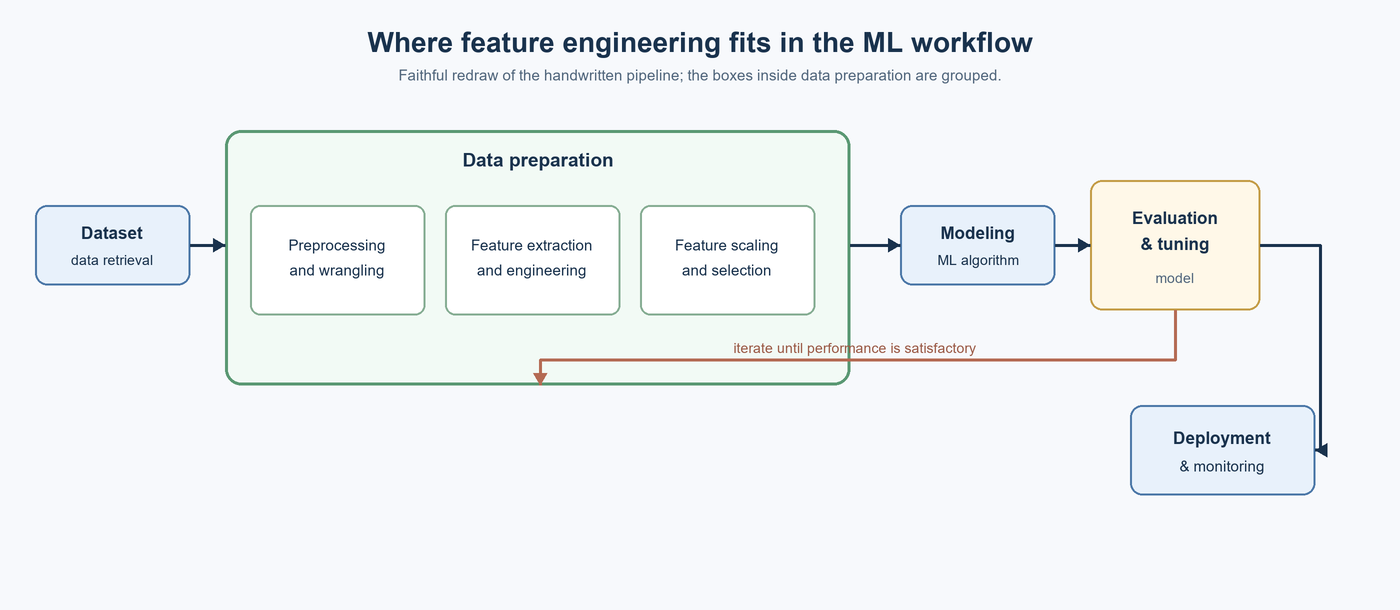

**This workflow shows where EDA fits: inspect the retrieved data, prepare features, train and evaluate a model, then use evaluation and monitoring to guide further preparation.**